<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# **Procesamiento de Lenguaje Natural**
## **Desafio, Traductor**

**Este desafío puede realizarse de manera individual o en pareja. En caso de realizarlo en pareja, solo uno de los integrantes deberá subir el desafío.**


Nombre(s):
* Franco Morero

### **Consigna**

* Replicar el modelo traductor desarrollado en clase (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### **Actividades opcionales**

* Incorporar embeddings preentrenados para ambos idiomas y evaluar su efecto sobre el rendimiento del modelo.
* Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).
* Implementar y entrenar una versión equivalente del modelo utilizando PyTorch, comparando los resultados con la implementación original.

---

**Resolución**

Primero replico la configuración de clase como punto de partida y después la entreno con todo el corpus y secuencias más largas. Con eso comparo 128, 256 y 512 unidades en las LSTM, y con la mejor pruebo embeddings preentrenados para los dos idiomas, word2vec para inglés y español. Para evaluar uso la perplejidad en validación y BLEU sobre un test que el modelo nunca vio.

Como corpus uso la última versión de spa-eng de manythings.org, que tiene 144.215 pares de frases, en vez de los 10.000 que usa el notebook de clase.

De las actividades opcionales, además de los embeddings preentrenados comparo greedy contra muestreo con temperatura y beam search, y replico el modelo directamente en PyTorch.

Para entrenar en la GPU del M1 Pro uso keras 3 con el backend de torch.

In [1]:
import os

os.environ["KERAS_BACKEND"] = "torch"  # env var antes de importar keras

In [2]:
import io
import json
import pickle
import re
import time
import urllib.request
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import keras
from keras import layers
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

In [3]:
keras.utils.set_random_seed(42)

print(f"Backend: {keras.backend.backend()}")
print(f"MPS disponible: {torch.backends.mps.is_available()}")
print(f"Device: {keras.ops.zeros(1).device}")

Backend: torch
MPS disponible: True
Device: mps:0


### Carga del corpus

Bajo spa-eng.zip de manythings.org, que es la última versión del dataset. El servidor rechaza los pedidos que no parecen de un navegador, así que le paso un User-Agent de Chrome. Cada línea tiene la frase en inglés, la traducción al español y la atribución, separadas por tabs, y me quedo con las dos primeras columnas.

In [4]:
URL_CORPUS = "https://www.manythings.org/anki/spa-eng.zip"
USER_AGENT = ("Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 "
              "(KHTML, like Gecko) Chrome/126.0 Safari/537.36")

if not Path("spa-eng/spa.txt").exists():
    pedido = urllib.request.Request(URL_CORPUS, headers={"User-Agent": USER_AGENT})
    with urllib.request.urlopen(pedido) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall("spa-eng")

lineas = Path("spa-eng/spa.txt").read_text(encoding="utf-8").splitlines()
pares = [tuple(l.split("\t")[:2]) for l in lineas]

print(f"Cantidad de pares: {len(pares)}")
print(f"Frases en ingles distintas: {len(set(en for en, _ in pares))}")
for en, es in pares[::30000]:
    print(f"{en}  ->  {es}")

Cantidad de pares: 144215
Frases en ingles distintas: 121487
Go.  ->  Ve.
He thinks I love her.  ->  Él piensa que la amo.
Can I ask a quick question?  ->  ¿Puedo hacer una pregunta rápida?
I consider him a great scientist.  ->  Le considero un gran científico.
Some of my friends can speak English well.  ->  Algunos amigos míos hablan bien inglés.


Tokenizo a nivel palabra. Paso todo a minúsculas y saco los signos de puntuación (incluidos ¿ y ¡), pero dejo el apóstrofe para que "don't" quede como una sola palabra. 

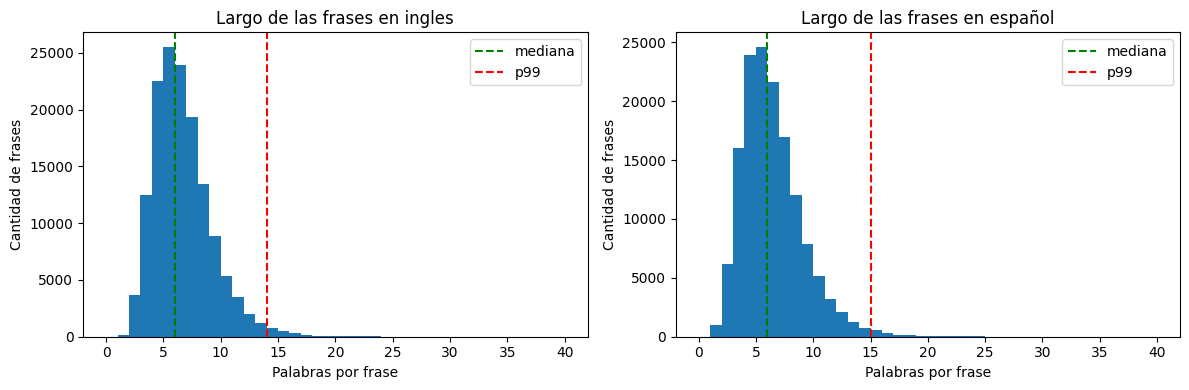

,ingles,español
count,144215.0,144215.0
mean,6.2,6.0
std,2.6,2.7
min,1.0,1.0
50%,6.0,6.0
90%,9.0,9.0
99%,14.0,15.0
99.9%,20.0,21.0
max,70.0,68.0


In [5]:
FILTROS = re.compile(r"[!\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~¿¡«»“”…]")


def limpiar(texto):
    """Minusculas, sin puntuacion y separado en palabras."""
    return FILTROS.sub(" ", texto.lower()).split()


pares_tok = [(limpiar(en), limpiar(es)) for en, es in pares]
largos_en = [len(en) for en, _ in pares_tok]
largos_es = [len(es) for _, es in pares_tok]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for ax, largos, idioma in [(ax1, largos_en, "ingles"), (ax2, largos_es, "español")]:
    ax.hist(largos, bins=range(0, 41))
    ax.axvline(np.median(largos), color="green", linestyle="--", label="mediana")
    ax.axvline(np.percentile(largos, 99), color="red", linestyle="--", label="p99")
    ax.set_xlabel("Palabras por frase")
    ax.set_ylabel("Cantidad de frases")
    ax.set_title(f"Largo de las frases en {idioma}")
    ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({"ingles": largos_en, "español": largos_es}).describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1)

### Split de train, validación y test

Muchas frases en inglés aparecen varias veces con distintas traducciones al español. Si separo por par, la misma frase en inglés puede quedar en train y en test con otra traducción, y el modelo se evalúa con frases que ya vio. Por eso separo por frase en inglés. Todas las traducciones de una misma frase quedan en el mismo conjunto de evaluación.

Dejo 2000 frases en inglés para test y un 10% del resto para validación.

In [7]:
N_TEST = 2000

traducciones = defaultdict(list)  # frase en ingles -> todas sus traducciones
for (en, es), (en_tok, es_tok) in zip(pares, pares_tok):
    traducciones[en].append((en_tok, es_tok))

frases_en = sorted(traducciones)
rng = np.random.default_rng(42)
rng.shuffle(frases_en)

n_val = int((len(frases_en) - N_TEST) * 0.1)
frases_test = frases_en[:N_TEST]
frases_val = frases_en[N_TEST:N_TEST + n_val]
frases_train = frases_en[N_TEST + n_val:]


def aplanar(frases):
    """Lista de pares tokenizados de un conjunto de frases en ingles, mezclados."""
    salida = [par for f in frases for par in traducciones[f]]
    rng.shuffle(salida)
    return salida


train_pares, val_pares = aplanar(frases_train), aplanar(frases_val)
test_en = [traducciones[f][0][0] for f in frases_test]
test_refs = [[es for _, es in traducciones[f]] for f in frases_test]  # referencias multiples

print(f"Pares train: {len(train_pares)} | val: {len(val_pares)} | frases test: {len(test_en)}")
print(f"Traducciones promedio por frase en ingles de test: {np.mean([len(r) for r in test_refs]):.2f}")

Pares train: 127738 | val: 14105 | frases test: 2000
Traducciones promedio por frase en ingles de test: 1.19


### Vocabulario y secuencias

Armo un vocabulario por idioma con las palabras más frecuentes de train. Los índices 0 a 3 quedan reservados para padding, inicio de frase, fin de frase y palabra desconocida.

El encoder recibe la frase en inglés con padding adelante, así el último estado de la LSTM es el de la última palabra real. El decoder, en cambio, recibe la frase en español con padding atrás y tiene que predecir la misma frase corrida un lugar. 

In [10]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3
ESPECIALES = ["<pad>", "<sos>", "<eos>", "<unk>"]


def armar_vocab(frases, max_vocab):
    """Diccionario palabra -> indice con las max_vocab mas frecuentes, especiales incluidos."""
    conteo = Counter(w for f in frases for w in f)
    palabras = [w for w, _ in conteo.most_common(max_vocab - len(ESPECIALES))]
    return {w: i for i, w in enumerate(ESPECIALES + palabras)}


def a_indices(frase, vocab):
    return [vocab.get(w, UNK) for w in frase]


def armar_datos(pares_tok, vocab_en, vocab_es, max_len_en, max_len_es):
    """Arrays de entrada del encoder, entrada del decoder, target y sample weight."""
    pad = keras.utils.pad_sequences
    enc = pad([a_indices(en, vocab_en) for en, _ in pares_tok], maxlen=max_len_en, truncating="post")
    dec_in = pad([[SOS] + a_indices(es, vocab_es) for _, es in pares_tok], maxlen=max_len_es, padding="post", truncating="post")
    dec_out = pad([a_indices(es, vocab_es) + [EOS] for _, es in pares_tok], maxlen=max_len_es, padding="post", truncating="post")
    return {"x": (enc, dec_in), "y": dec_out, "peso": (dec_out != PAD).astype("float32")}

### Modelo

La arquitectura es un encoder LSTM que lee la frase en inglés y pasa sus estados h y c como estado inicial de un decoder LSTM, que genera la frase en español con teacher forcing.
* Encoder: embedding, dropout de 0.3 y LSTM con return_state, de la que solo uso los estados finales.
* Decoder: embedding, dropout de 0.3, LSTM con return_sequences inicializada con los estados del encoder y Dense con softmax sobre el vocabulario en español.
* Embeddings: si le paso una matriz arranca con esos pesos, y con entrenable decido si se congelan o se ajustan.
* Loss: sparse categorical crossentropy, así el target va como índices y no hace falta el one-hot del notebook de clase, que con 20.000 palabras no entra en memoria. La reducción promedia solo sobre los tokens con peso, por lo que los de padding que valen 0 no cuentan en la loss.
* Accuracy: por token y sin contar el padding.
* Optimizador: Adam con learning rate 5e-4, ReduceLROnPlateau y early stopping.

In [11]:
def armar_modelo(vocab_en_size, vocab_es_size, unidades, dim_en=300, dim_es=300,
                 matriz_en=None, matriz_es=None, entrenable=True):
    """Encoder-decoder LSTM, opcionalmente con embeddings preentrenados."""
    def embedding(vocab_size, dim, matriz, nombre):
        if matriz is None:
            return layers.Embedding(vocab_size, dim, name=nombre)
        return layers.Embedding(vocab_size, matriz.shape[1], name=nombre, trainable=entrenable,
                                embeddings_initializer=keras.initializers.Constant(matriz))

    enc_entrada = keras.Input(shape=(None,), name="enc_entrada")
    x = embedding(vocab_en_size, dim_en, matriz_en, "enc_emb")(enc_entrada)
    x = layers.Dropout(0.3)(x)
    _, h, c = layers.LSTM(unidades, return_state=True, name="enc_lstm")(x)

    dec_entrada = keras.Input(shape=(None,), name="dec_entrada")
    y = embedding(vocab_es_size, dim_es, matriz_es, "dec_emb")(dec_entrada)
    y = layers.Dropout(0.3)(y)
    y, _, _ = layers.LSTM(unidades, return_sequences=True, return_state=True, name="dec_lstm")(y, initial_state=[h, c])
    salida = layers.Dense(vocab_es_size, activation="softmax", name="dec_dense")(y)

    modelo = keras.Model([enc_entrada, dec_entrada], salida)
    modelo.compile(
        loss=keras.losses.SparseCategoricalCrossentropy(reduction="mean_with_sample_weight"),
        optimizer=keras.optimizers.Adam(learning_rate=5e-4),
        weighted_metrics=["accuracy"],
    )
    return modelo

### Entrenamiento

Uso el mismo callback de perplejidad que en el Desafío 3, que la calcula como la exponencial de la loss de validación. El mejor modelo se guarda en modelos_desafio4 junto con su historia. Si ya existen los cargo en vez de reentrenar, así puedo volver a correr el notebook sin esperar otra vez todos los entrenamientos.

In [12]:
EPOCAS = 20
PACIENCIA = 3
BATCH_SIZE = 256
CARPETA = Path("modelos_desafio4")
CARPETA.mkdir(exist_ok=True)


class Perplejidad(keras.callbacks.Callback):
    """Agrega val_ppl = exp(val_loss) a los logs de cada epoca."""

    def on_epoch_end(self, epoch, logs=None):
        logs["val_ppl"] = float(np.exp(logs["val_loss"]))
        print(f" - val_ppl: {logs['val_ppl']:.2f}")


def entrenar(nombre, modelo, train, val, epocas=EPOCAS, batch_size=BATCH_SIZE):
    """Entrena con early stopping o carga el modelo y la historia si ya estan guardados."""
    ruta_modelo = CARPETA / f"traductor_{nombre}.keras"
    ruta_historia = CARPETA / f"historia_{nombre}.json"
    if ruta_modelo.exists() and ruta_historia.exists():
        print(f"Cargo {ruta_modelo} sin reentrenar")
        return keras.models.load_model(ruta_modelo), json.loads(ruta_historia.read_text())

    callbacks = [
        Perplejidad(),  # va primero para que los siguientes ya vean val_ppl
        keras.callbacks.ModelCheckpoint(ruta_modelo, monitor="val_loss", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True),
    ]
    inicio = time.time()
    historia = modelo.fit(
        train["x"], train["y"], sample_weight=train["peso"],
        validation_data=(val["x"], val["y"], val["peso"]),
        epochs=epocas, batch_size=batch_size, callbacks=callbacks, verbose=2,
    ).history
    historia = {k: [float(v) for v in vs] for k, vs in historia.items()}
    historia["minutos"] = (time.time() - inicio) / 60
    historia["parametros"] = modelo.count_params()
    ruta_historia.write_text(json.dumps(historia))
    print(f"Tiempo: {historia['minutos']:.1f} min | Mejor perplejidad: {min(historia['val_ppl']):.2f}")
    return modelo, historia

### Inferencia y BLEU

Para traducir armo dos modelos que reutilizan las capas entrenadas. El encoder devuelve los estados de la frase en inglés y el decoder avanza de a un token con los estados del paso anterior. Arranca con el token de inicio, en cada paso elige la palabra más probable (greedy) y corta en el fin de frase o al llegar al largo máximo. Para no traducir de a una frase, el greedy lo hago en batch.

Como métrica de traducción uso BLEU score del corpus, que mide cuántos n-gramas de 1 a 4 palabras de la traducción aparecen en las referencias y penaliza las traducciones muy cortas. Uso todas las traducciones que tiene cada frase en inglés de test como referencias y el smoothing de nltk para que las frases cortas sin 4-gramas en común no den cero.

In [13]:
def modelos_inferencia(modelo):
    """Encoder que devuelve los estados y decoder de un paso, con las capas entrenadas."""
    unidades = modelo.get_layer("dec_lstm").units
    enc_entrada = keras.Input(shape=(None,))
    _, h, c = modelo.get_layer("enc_lstm")(modelo.get_layer("enc_emb")(enc_entrada))
    encoder = keras.Model(enc_entrada, [h, c])

    dec_entrada = keras.Input(shape=(1,))
    h_in, c_in = keras.Input(shape=(unidades,)), keras.Input(shape=(unidades,))
    y, h_out, c_out = modelo.get_layer("dec_lstm")(modelo.get_layer("dec_emb")(dec_entrada), initial_state=[h_in, c_in])
    decoder = keras.Model([dec_entrada, h_in, c_in], [modelo.get_layer("dec_dense")(y), h_out, c_out])
    return encoder, decoder


def cortar(indices, idx2es):
    """Pasa indices a palabras hasta el primer fin de frase."""
    palabras = []
    for i in indices:
        if i == EOS:
            break
        if i != PAD:
            palabras.append(idx2es[int(i)])
    return palabras


def greedy_batch(encoder, decoder, enc_x, idx2es, max_len, batch=512):
    """Traduce un array de frases codificadas eligiendo la palabra mas probable en cada paso."""
    traducciones_out = []
    for i in range(0, len(enc_x), batch):
        h, c = encoder.predict_on_batch(enc_x[i:i + batch])
        token = np.full((len(h), 1), SOS)
        pasos = []
        for _ in range(max_len):
            probs, h, c = decoder.predict_on_batch([token, h, c])
            token = np.argmax(probs[:, -1], axis=-1)[:, None]
            pasos.append(token[:, 0])
        traducciones_out += [cortar(fila, idx2es) for fila in np.stack(pasos, axis=1)]
    return traducciones_out


def bleu(hipotesis, referencias):
    """BLEU de corpus de 0 a 100 con referencias multiples."""
    return 100 * corpus_bleu(referencias, hipotesis, smoothing_function=SmoothingFunction().method1)

Para comparar los experimentos armo dos funciones. Una evalúa un modelo con greedy sobre las frases de test y calcula el BLEU. La otra arma los gráficos de loss y perplejidad y la tabla resumen.

In [33]:
resultados = {}  # nombre -> historia, bleu, traducciones de test y config


def codificar_test(vocab_en, max_len_en):
    return keras.utils.pad_sequences([a_indices(f, vocab_en) for f in test_en], maxlen=max_len_en, truncating="post")


def evaluar(nombre, modelo, historia, vocab_en, vocab_es, max_len_en, max_len_es):
    """Traduce test con greedy, calcula BLEU y guarda todo en resultados."""
    encoder, decoder = modelos_inferencia(modelo)
    idx2es = {i: w for w, i in vocab_es.items()}
    hipotesis = greedy_batch(encoder, decoder, codificar_test(vocab_en, max_len_en), idx2es, max_len_es)
    resultados[nombre] = {
        "historia": historia, "bleu": bleu(hipotesis, test_refs), "hipotesis": hipotesis,
        "vocab_en": vocab_en, "vocab_es": vocab_es, "max_len_en": max_len_en, "max_len_es": max_len_es,
    }
    print(f"{nombre} | BLEU test: {resultados[nombre]['bleu']:.2f}")


def tabla_resumen(nombres):
    return pd.DataFrame({
        n: {
            "mejor_ppl": min(resultados[n]["historia"]["val_ppl"]),
            "mejor_epoca": int(np.argmin(resultados[n]["historia"]["val_ppl"])) + 1,
            "epocas": len(resultados[n]["historia"]["val_ppl"]),
            "minutos": resultados[n]["historia"]["minutos"],
            "parametros": int(resultados[n]["historia"]["parametros"]),
            "val_acc": max(resultados[n]["historia"]["val_accuracy"]),
            "bleu": resultados[n]["bleu"],
        }
        for n in nombres
    }).T.round(2)


def graficar(nombres, titulo):
    """Loss de train y validacion, perplejidad de validacion y BLEU de test."""
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))
    for n in nombres:
        h = resultados[n]["historia"]
        epocas = range(1, len(h["loss"]) + 1)
        linea, = ax1.plot(epocas, h["loss"], label=f"{n} train")
        ax1.plot(epocas, h["val_loss"], linestyle="--", color=linea.get_color(), label=f"{n} val")
        ax2.plot(epocas, h["val_ppl"], marker="o", label=n)
        ax3.bar(n, resultados[n]["bleu"], color=linea.get_color())
    ax1.set_xlabel("Epoca")
    ax1.set_ylabel("Loss")
    ax1.set_title("Loss de train y validacion")
    ax1.legend(fontsize=8)
    ax2.set_xlabel("Epoca")
    ax2.set_ylabel("Perplejidad")
    ax2.set_title("Perplejidad en validacion")
    ax2.legend()
    ax3.set_ylabel("BLEU")
    ax3.set_title("BLEU en test (greedy)")
    ax3.tick_params(axis="x", rotation=20)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

### Réplica del modelo de clase

Primero replico la configuración del notebook de clase como punto de partida, con 10.000 pares, vocabulario de máximo 8.000 palabras por idioma, largo máximo de 20 palabras en inglés y 22 en español, y 256 unidades en las LSTM. También uso el batch de 64 y las 30 épocas de clase. Una diferencia es que en clase el encoder usa GloVe congelado con 50 dimensiones y acá los embeddings arrancan al azar con más dimensiones, porque los preentrenados los pruebo más adelante por separado. Lo evalúo con el mismo set de test que el resto para poder comparar.

In [34]:
N_CLASE = 10_000
VOCAB_CLASE = 8_000
LARGO_EN_CLASE, LARGO_ES_CLASE = 20, 22
DIM_EN, DIM_ES = 300, 400  # mismas dimensiones que los embeddings preentrenados
LSTM_UNIDADES = 256

train_clase_pares = train_pares[:N_CLASE]
vocab_en_clase = armar_vocab([en for en, _ in train_clase_pares], VOCAB_CLASE)
vocab_es_clase = armar_vocab([es for _, es in train_clase_pares], VOCAB_CLASE)
train_clase = armar_datos(train_clase_pares, vocab_en_clase, vocab_es_clase, LARGO_EN_CLASE, LARGO_ES_CLASE)
val_clase = armar_datos(val_pares, vocab_en_clase, vocab_es_clase, LARGO_EN_CLASE, LARGO_ES_CLASE)

print(f"Vocabulario EN: {len(vocab_en_clase)} | ES: {len(vocab_es_clase)}")
modelo = armar_modelo(len(vocab_en_clase), len(vocab_es_clase), LSTM_UNIDADES, DIM_EN, DIM_ES)
modelo.summary()

Vocabulario EN: 4892 | ES: 7714


Model: "functional_24"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ enc_entrada         │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_entrada         │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_emb (Embedding) │ (None, None, 300) │  1,467,600 │ enc_entrada[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_emb (Embedding) │ (None, None, 400) │  3,085,600 │ dec_entrada[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, None, 300) │          0 │ enc_emb[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_17          │ (None, None, 400) │          0 │ dec_emb[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_lstm (LSTM)     │ [(None, 256),     │    570,368 │ dropout_16[0][0]  │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_lstm (LSTM)     │ [(None, None,     │    672,768 │ dropout_17[0][0], │
│                     │ 256), (None,      │            │ enc_lstm[0][1],   │
│                     │ 256), (None,      │            │ enc_lstm[0][2]    │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_dense (Dense)   │ (None, None,      │  1,982,498 │ dec_lstm[0][0]    │
│                     │ 7714)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,778,834 (29.67 MB)

 Trainable params: 7,778,834 (29.67 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
modelo, historia = entrenar("clase", modelo, train_clase, val_clase, epocas=30, batch_size=64)
evaluar("clase", modelo, historia, vocab_en_clase, vocab_es_clase, LARGO_EN_CLASE, LARGO_ES_CLASE)

Cargo modelos_desafio4/traductor_clase.keras sin reentrenar
clase | BLEU test: 2.88


Observaciones
* Aun con el batch de 64 y 30 épocas la réplica de clase queda muy lejos de traducir bien. La perplejidad de validación se estanca alrededor de 113 en las últimas épocas mientras la loss de train sigue bajando, así que con 10.000 pares el modelo ya empieza a memorizar.
* Con 10.000 pares el vocabulario en inglés tiene menos de 5.000 palabras, por lo que una parte de las frases de test tiene palabras que el modelo nunca vio y le llegan como desconocidas.

### Más datos y secuencias más largas

Ahora uso todos los pares de train y subo el largo máximo. El vocabulario en inglés entra completo y el de español lo corto en las palabras más frecuentes, que cubren casi todos los tokens del corpus. El resto pasa a ser palabra desconocida.

In [36]:
VOCAB_EN = 15_000
VOCAB_ES = 15_000
MAX_LEN_EN, MAX_LEN_ES = 25, 27

vocab_en = armar_vocab([en for en, _ in train_pares], VOCAB_EN)
vocab_es = armar_vocab([es for _, es in train_pares], VOCAB_ES)
idx2es = {i: w for w, i in vocab_es.items()}
train = armar_datos(train_pares, vocab_en, vocab_es, MAX_LEN_EN, MAX_LEN_ES)
val = armar_datos(val_pares, vocab_en, vocab_es, MAX_LEN_EN, MAX_LEN_ES)
enc_test = codificar_test(vocab_en, MAX_LEN_EN)

conteo_es = Counter(w for _, es in train_pares for w in es)
cobertura_es = sum(conteo_es[w] for w in vocab_es) / sum(conteo_es.values())
largos_train = np.array([len(es) for _, es in train_pares])

print(f"Vocabulario EN: {len(vocab_en)} | ES: {len(vocab_es)} (de {len(conteo_es)} palabras distintas)")
print(f"Tokens en español cubiertos por el vocabulario: {cobertura_es:.2%}")
print(f"Frases en español que entran sin cortar: {np.mean(largos_train + 1 <= MAX_LEN_ES):.3%}")
print(f"Pares train: {len(train['y'])} | val: {len(val['y'])}")

Vocabulario EN: 13874 | ES: 15000 (de 26957 palabras distintas)
Tokens en español cubiertos por el vocabulario: 98.31%
Frases en español que entran sin cortar: 99.973%
Pares train: 127738 | val: 14105


### Cantidad de neuronas en las capas recurrentes

Con el corpus completo entreno la misma arquitectura con 128, 256 y 512 unidades en las LSTM. Las unidades definen el tamaño del estado h y c, que es todo lo que el decoder recibe de la frase en inglés.

In [37]:
UNIDADES = [128, 256, 512]

for u in UNIDADES:
    nombre = f"lstm_{u}"
    modelo = armar_modelo(len(vocab_en), len(vocab_es), u, DIM_EN, DIM_ES)
    modelo, historia = entrenar(nombre, modelo, train, val)
    evaluar(nombre, modelo, historia, vocab_en, vocab_es, MAX_LEN_EN, MAX_LEN_ES)

Cargo modelos_desafio4/traductor_lstm_128.keras sin reentrenar
lstm_128 | BLEU test: 10.05
Cargo modelos_desafio4/traductor_lstm_256.keras sin reentrenar
lstm_256 | BLEU test: 18.90
Cargo modelos_desafio4/traductor_lstm_512.keras sin reentrenar
lstm_512 | BLEU test: 20.45


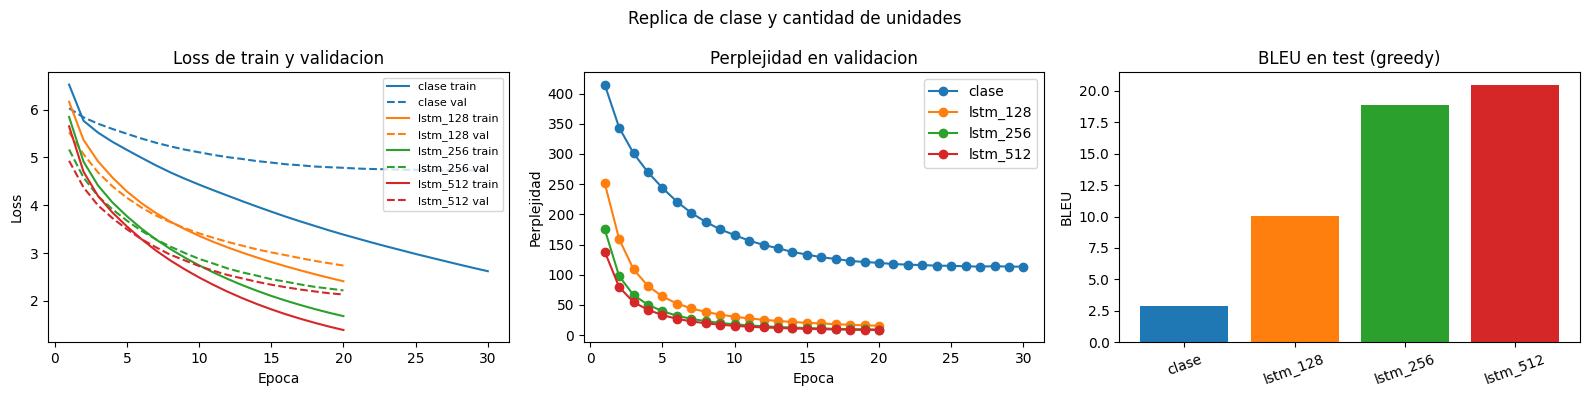

In [38]:
nombres_unidades = ["clase"] + [f"lstm_{u}" for u in UNIDADES]
graficar(nombres_unidades, "Replica de clase y cantidad de unidades")

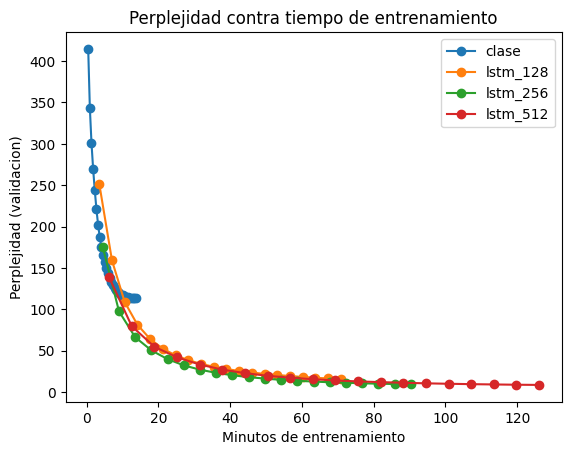

,mejor_ppl,mejor_epoca,epocas,minutos,parametros,val_acc,bleu
clase,113.30,30.0,30.0,13.77,7778834.0,0.33,2.88
lstm_128,15.49,20.0,20.0,70.86,12587696.0,0.50,10.05
lstm_256,9.22,20.0,20.0,90.36,15260336.0,0.57,18.90
lstm_512,8.46,20.0,20.0,126.11,21392048.0,0.59,20.45


In [39]:
# perplejidad contra tiempo acumulado de entrenamiento
for n in nombres_unidades:
    h = resultados[n]["historia"]
    minutos = np.arange(1, len(h["val_ppl"]) + 1) * h["minutos"] / len(h["val_ppl"])
    plt.plot(minutos, h["val_ppl"], marker="o", label=n)
plt.xlabel("Minutos de entrenamiento")
plt.ylabel("Perplejidad (validacion)")
plt.title("Perplejidad contra tiempo de entrenamiento")
plt.legend()
plt.show()

tabla_resumen(nombres_unidades)

Observaciones
* Pasar de 10.000 a casi 128.000 pares de entrenamiento es el cambio que más pesa. Con la misma arquitectura de 256 unidades el BLEU pasa de 2,9 a 18,9 y la perplejidad de 113 a 9,2.
* Más unidades siempre mejoran. De 128 a 256 el BLEU casi se duplica (10,1 a 18,9) y de 256 a 512 la mejora es más chica (18,9 a 20,5). Parece que a partir de 256 el cuello de botella deja de ser el tamaño del estado.
* Ningún modelo cortó por early stopping. Los tres llegan a la época 20 con la loss de validación todavía bajando y el learning rate nunca se redujo, así que con más épocas probablemente mejoren todos. No los dejé seguir porque cada uno ya tarda entre una y dos horas.
* En ninguno se ve sobreajuste. La loss de train y la de validación bajan juntas, y la distancia entre las dos crece con las unidades, que es lo esperable con más parámetros.
* El costo crece con las unidades. El de 512 tiene un 40% más de parámetros que el de 256 y tarda 126 minutos contra 90. En la curva de perplejidad contra minutos el de 256 llega antes a la misma perplejidad, y el de 512 solo lo supera porque entrena más tiempo.

Un número de BLEU por modelo esconde cómo cambia la calidad de las traducciones en base al largo de la frase. Para verlo agrupo las frases de test por cantidad de palabras en inglés y calculo el BLEU de cada grupo.

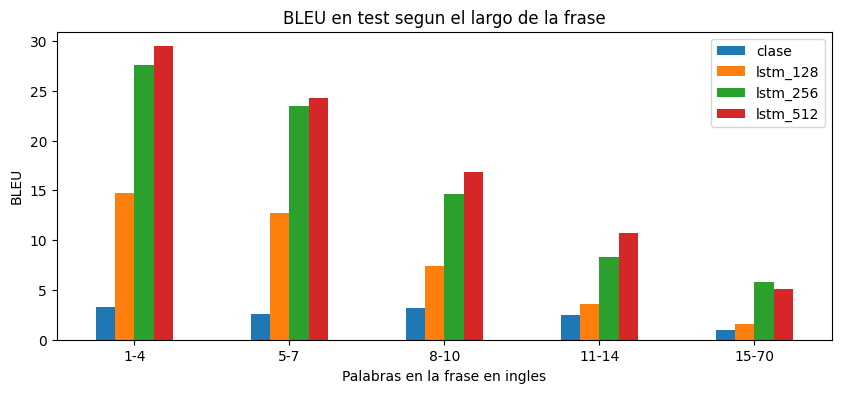

Frases de test por grupo: {'1-4': 497, '5-7': 978, '8-10': 391, '11-14': 116, '15-70': 18}


,clase,lstm_128,lstm_256,lstm_512
1-4,3.29,14.74,27.58,29.45
5-7,2.59,12.73,23.45,24.29
8-10,3.17,7.41,14.61,16.85
11-14,2.43,3.61,8.26,10.67
15-70,0.99,1.55,5.77,5.08


In [18]:
GRUPOS_LARGO = [(1, 4), (5, 7), (8, 10), (11, 14), (15, 70)]


def bleu_por_largo(nombre):
    hip = resultados[nombre]["hipotesis"]
    salida = {}
    for desde, hasta in GRUPOS_LARGO:
        idx = [i for i, f in enumerate(test_en) if desde <= len(f) <= hasta]
        salida[f"{desde}-{hasta}"] = bleu([hip[i] for i in idx], [test_refs[i] for i in idx])
    return salida


df_largo = pd.DataFrame({n: bleu_por_largo(n) for n in nombres_unidades})
df_largo.plot(kind="bar", figsize=(10, 4), rot=0)
plt.xlabel("Palabras en la frase en ingles")
plt.ylabel("BLEU")
plt.title("BLEU en test segun el largo de la frase")
plt.show()

print("Frases de test por grupo:", {f"{d}-{h}": sum(d <= len(f) <= h for f in test_en) for d, h in GRUPOS_LARGO})
df_largo.round(2)

Observaciones
* El grupo de más de 15 palabras tiene solo 18 frases en test, por lo que no es útil para conclusiones.
* En todos los modelos el BLEU baja a medida que la frase es más larga. El de 512 pasa de 29,5 en frases de hasta 4 palabras a 10,7 en las de 11 a 14.
* Más unidades ayudan sobre todo en las frases largas. De 256 a 512 el grupo de 11 a 14 palabras sube de 8,3 a 10,7 y el de 1 a 4 solo de 27,6 a 29,5.

Me quedo con la cantidad de unidades para la LSTM que logra mejor BLEU en test para los experimentos que siguen.

In [41]:
UNIDADES_FINAL = max(UNIDADES, key=lambda u: resultados[f"lstm_{u}"]["bleu"])
print(f"Unidades elegidas: {UNIDADES_FINAL}")

Unidades elegidas: 512


### Embeddings preentrenados

Hasta acá los embeddings de los dos idiomas arrancan al azar y se aprenden solo con las frases del corpus, que son cortas y de vocabulario simple. Pruebo arrancar con embeddings entrenados sobre corpus mucho más grandes, que ya traen la semántica de cada palabra.
* Inglés: word2vec de Google News (https://code.google.com/archive/p/word2vec/), 300 dimensiones, 3 millones de palabras y frases entrenadas sobre unos 100.000 millones de palabras de noticias. Distingue mayúsculas y no tiene algunas stopwords como "a", "and", "of" y "to".
* Español: Spanish 3B Word2Vec Embeddings de Almeida y Bilbao (https://zenodo.org/record/1410403), 400 dimensiones, entrenados con gensim sobre más de 3.000 millones de palabras de noticias, Wikipedia, el BOE y literatura. Está en minúsculas y con tildes, como la tokenización de este trabajo.

Los dos archivos originales pesan varios GB, así que los bajo una vez, me quedo con las 200.000 palabras más frecuentes de cada uno y los guardo recortados en embeddings/. Con eso cubro el vocabulario del corpus. 

In [43]:
from gensim.models import KeyedVectors

CARPETA_EMB = Path("embeddings")
N_PALABRAS_EMB = 200_000
URL_EN = "https://github.com/RaRe-Technologies/gensim-data/releases/download/word2vec-google-news-300/word2vec-google-news-300.gz"
URL_ES = "https://zenodo.org/api/records/1410403/files/keyed_vectors.zip/content"


def bajar(url, destino):
    if not destino.exists():
        print(f"Bajando {url}")
        urllib.request.urlretrieve(url, destino)


CARPETA_EMB.mkdir(exist_ok=True)
if not (CARPETA_EMB / "en_200k.bin").exists():
    bajar(URL_EN, CARPETA_EMB / "word2vec-google-news-300.gz")
    kv = KeyedVectors.load_word2vec_format(CARPETA_EMB / "word2vec-google-news-300.gz", binary=True, limit=N_PALABRAS_EMB)
    kv.save_word2vec_format(CARPETA_EMB / "en_200k.bin", binary=True)
if not (CARPETA_EMB / "es_200k.bin").exists():
    bajar(URL_ES, CARPETA_EMB / "keyed_vectors.zip")
    zipfile.ZipFile(CARPETA_EMB / "keyed_vectors.zip").extractall(CARPETA_EMB / "es_kv")
    ruta_kv = next((CARPETA_EMB / "es_kv").rglob("complete.kv"))

    # es un pickle de gensim 3 que gensim 4 no abre, me quedo con la lista de palabras y el npy
    class Generica:
        def __setstate__(self, estado):
            self.__dict__.update(estado)

    class Despicklador(pickle.Unpickler):
        def find_class(self, modulo, nombre):
            return type(nombre, (Generica,), {}) if modulo.startswith("gensim") else super().find_class(modulo, nombre)

    with open(ruta_kv, "rb") as f:
        viejo = Despicklador(f, encoding="latin1").load()
    vectores = np.load(f"{ruta_kv}.vectors.npy", mmap_mode="r")
    kv = KeyedVectors(viejo.vector_size)
    kv.add_vectors(viejo.index2word[:N_PALABRAS_EMB], np.asarray(vectores[:N_PALABRAS_EMB], dtype="float32"))
    kv.save_word2vec_format(CARPETA_EMB / "es_200k.bin", binary=True)

w2v_en = KeyedVectors.load_word2vec_format(CARPETA_EMB / "en_200k.bin", binary=True)
w2v_es = KeyedVectors.load_word2vec_format(CARPETA_EMB / "es_200k.bin", binary=True)
print(f"EN: {len(w2v_en)} palabras de {w2v_en.vector_size} dimensiones")
print(f"ES: {len(w2v_es)} palabras de {w2v_es.vector_size} dimensiones")
print(w2v_es.most_similar("perro", topn=5))

EN: 200000 palabras de 300 dimensiones
ES: 200000 palabras de 400 dimensiones
[('gato', 0.8528096079826355), ('cachorro', 0.8198988437652588), ('perrito', 0.8108552098274231), ('mastín', 0.7777805328369141), ('perrillo', 0.7749276757240295)]


Armo la matriz de embeddings de cada idioma con mi vocabulario. Las palabras que no están arrancan al azar con la misma escala que los vectores preentrenados y el padding queda en cero.

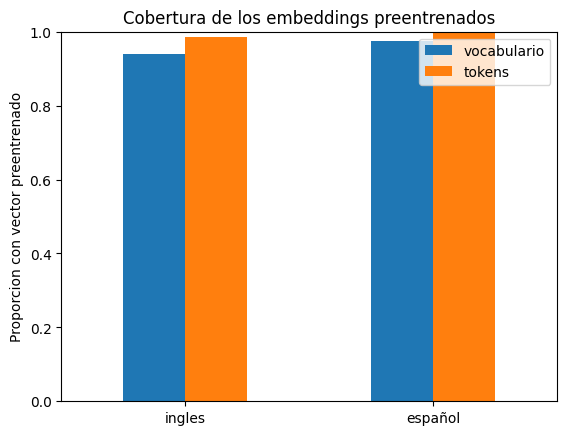

Sin vector EN (854): ["that's", "tom's", "he's", "i'd", "there's", "couldn't", "wasn't", "aren't", "mary's", "haven't", "you've", "she's", "wouldn't", "shouldn't", "you'd", '30', "hasn't", "where's", "it'll", 'cannot', "should've", "weren't", "he'll", "he'd", "hadn't"]
Sin vector ES (365): ['necesitás', 'sentate', 'órale', 'pilchas', 'mostrame', 'pochoclo', 'llamá', 'pruébate', 'lavaste', 'escuchá', 'horneó', 'papión', 'tomémonos', 'suertudo', 'cacahuates', 'aventón', 'apurarte', 'desayunas', 'cedisteis', 'cenaste', 'poné', 'comprasteis', 'traeme', 'tírame', 'cerrá']


,ingles,español
vocabulario,0.938,0.976
tokens,0.985,0.999


In [44]:
def matriz_embeddings(vocab, kv):
    """Matriz vocab x dim con los vectores preentrenados y la lista de palabras que no estan."""
    rng_emb = np.random.default_rng(42)
    escala = kv.vectors.std()
    matriz = rng_emb.normal(0, escala, (len(vocab), kv.vector_size)).astype("float32")
    matriz[PAD] = 0
    faltan = []
    for w, i in vocab.items():
        if i < len(ESPECIALES):
            continue
        for candidata in (w, w.capitalize(), w.upper()):
            if candidata in kv.key_to_index:
                matriz[i] = kv[candidata]
                break
        else:
            faltan.append(w)
    return matriz, faltan


matriz_en, faltan_en = matriz_embeddings(vocab_en, w2v_en)
matriz_es, faltan_es = matriz_embeddings(vocab_es, w2v_es)

conteo_en = Counter(w for en, _ in train_pares for w in en)
cobertura = pd.DataFrame({
    "ingles": {"vocabulario": 1 - len(faltan_en) / (len(vocab_en) - 4),
               "tokens": 1 - sum(conteo_en[w] for w in faltan_en) / sum(conteo_en[w] for w in vocab_en)},
    "español": {"vocabulario": 1 - len(faltan_es) / (len(vocab_es) - 4),
                "tokens": 1 - sum(conteo_es[w] for w in faltan_es) / sum(conteo_es[w] for w in vocab_es)},
})
cobertura.T.plot(kind="bar", rot=0, ylim=(0, 1))
plt.ylabel("Proporcion con vector preentrenado")
plt.title("Cobertura de los embeddings preentrenados")
plt.show()

print(f"Sin vector EN ({len(faltan_en)}): {sorted(faltan_en, key=lambda w: -conteo_en[w])[:25]}")
print(f"Sin vector ES ({len(faltan_es)}): {sorted(faltan_es, key=lambda w: -conteo_es[w])[:25]}")
cobertura.round(3)

Observaciones
* La cobertura es muy alta. El 98,5% de los tokens en inglés y el 99,9% en español tienen vector preentrenado.
* En inglés la mayoría de las palabras que faltan son contracciones como "that's", "i'd" o "couldn't". Google las separa de otra forma y además no tiene "a", "and", "of" ni "to", que son de las palabras más frecuentes del corpus. Esas arrancan al azar.
* En español lo que falta son voseos y palabras del español latino ("necesitás", "sentate", "pochoclo", "aventón", "cacahuates"), que no aparecen en el corpus con el que se entrenaron los embeddings.

Con la red LSTM con las unidades elegidas comparo tres variantes.
1. La primera es el modelo sin preentrenados del punto anterior. 
2. La segunda arranca con los vectores preentrenados y los deja congelados, así que solo aprenden las LSTM y la capa de salida. 
3. La tercera arranca igual pero deja que los embeddings se sigan ajustando con el corpus (fine tuning). 

Las dimensiones son las mismas en las tres, 300 en inglés y 400 en español, para que solo cambie la inicialización.

In [45]:
for nombre, entrenable in [("w2v_congelado", False), ("w2v_entrenable", True)]:
    modelo = armar_modelo(len(vocab_en), len(vocab_es), UNIDADES_FINAL,
                          matriz_en=matriz_en, matriz_es=matriz_es, entrenable=entrenable)
    modelo, historia = entrenar(nombre, modelo, train, val)
    evaluar(nombre, modelo, historia, vocab_en, vocab_es, MAX_LEN_EN, MAX_LEN_ES)

Cargo modelos_desafio4/traductor_w2v_congelado.keras sin reentrenar
w2v_congelado | BLEU test: 25.79
Cargo modelos_desafio4/traductor_w2v_entrenable.keras sin reentrenar
w2v_entrenable | BLEU test: 32.71


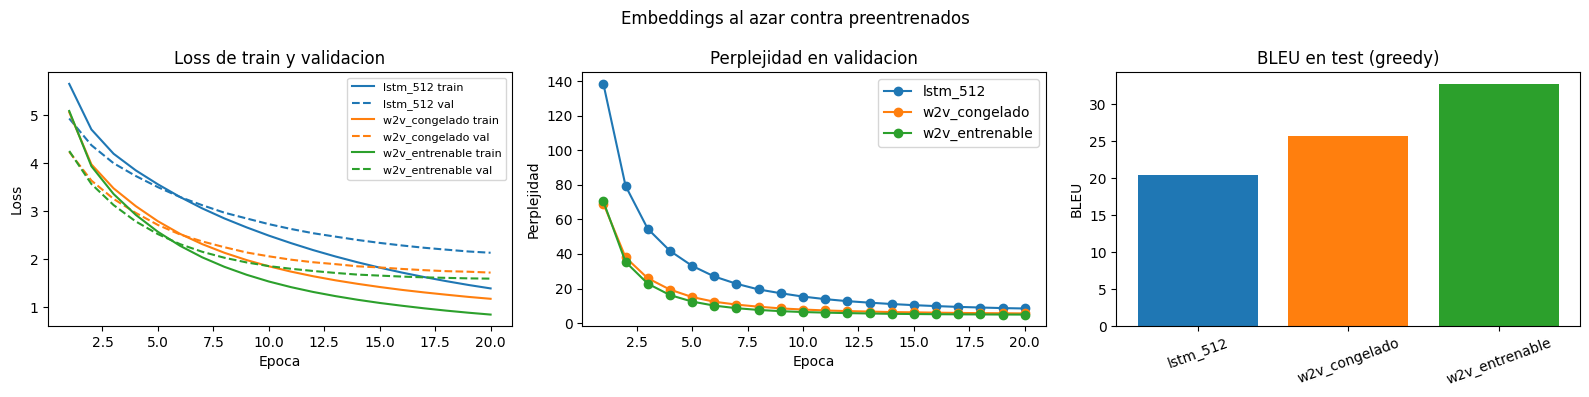

,mejor_ppl,mejor_epoca,epocas,minutos,parametros,val_acc,bleu
lstm_512,8.46,20.0,20.0,126.11,21392048.0,0.59,20.45
w2v_congelado,5.60,20.0,20.0,119.33,21392048.0,0.63,25.79
w2v_entrenable,4.93,20.0,20.0,126.52,21392048.0,0.67,32.71


In [46]:
nombres_emb = [f"lstm_{UNIDADES_FINAL}", "w2v_congelado", "w2v_entrenable"]
graficar(nombres_emb, "Embeddings al azar contra preentrenados")
tabla_resumen(nombres_emb)

Observaciones
* Los embeddings preentrenados mejoran todo. Con la misma arquitectura de 512 unidades el BLEU pasa de 20,5 a 25,8 con los vectores congelados y a 32,7 con los entrenables, y la perplejidad baja de 8,5 a 5,6 y 4,9.
* Los modelos con preentrenados arrancan mucho mejor. En la primera época la perplejidad de validación es la mitad que la del modelo al azar, y esa ventaja se mantiene hasta el final.
* Dejar que los embeddings se ajusten anda mejor que congelarlos. Los vectores de Google News y de Almeida y Bilbao se entrenaron para predecir contexto en noticias, no para traducir, y con fine tuning se pueden acomodar a la tarea. El costo es un poco más de sobreajuste, porque la distancia entre train y validación es más grande que con los vectores congelados.

### Traducciones de ejemplo

Para traducir texto nuevo uso la misma función de limpieza que en el entrenamiento y el greedy en batch con una sola frase. Muestro frases de test, que el modelo nunca vio, con las traducciones de la réplica de clase, del modelo sin preentrenados y de los dos con preentrenados.

In [49]:
def traducir(nombre, frases):
    """Traduce una lista de frases en ingles con el modelo guardado en resultados."""
    r = resultados[nombre]
    encoder, decoder = modelos_inferencia(modelos[nombre])
    enc_x = keras.utils.pad_sequences([a_indices(limpiar(f), r["vocab_en"]) for f in frases],
                                      maxlen=r["max_len_en"], truncating="post")
    idx2 = {i: w for w, i in r["vocab_es"].items()}
    return [" ".join(p) for p in greedy_batch(encoder, decoder, enc_x, idx2, r["max_len_es"])]


modelos = {n: keras.models.load_model(CARPETA / f"traductor_{n}.keras") for n in resultados}
nombres_ejemplos = ["clase", f"lstm_{UNIDADES_FINAL}", "w2v_congelado", "w2v_entrenable"]

N_EJEMPLOS = 8
idx_ejemplos = np.random.default_rng(7).choice(len(test_en), N_EJEMPLOS, replace=False)
for i in idx_ejemplos:
    print(f"EN: {' '.join(test_en[i])}")
    print(f"ES (referencia): {' | '.join(' '.join(r) for r in test_refs[i])}")
    for n in nombres_ejemplos:
        print(f"{n:>15}: {' '.join(resultados[n]['hipotesis'][i])}")
    print()

EN: i expect you know all about it
ES (referencia): espero que sepan todo al respecto | espero que sepas todo al respecto
          clase: creo que te lo que me gusta
       lstm_512: espero que todo lo que está pasando
  w2v_congelado: espero que todos sepan sobre eso
 w2v_entrenable: espero que todos sepan sobre ello

EN: what could i have done to prevent this
ES (referencia): qué podría haber hecho para evitar esto
          clase: si no me gusta hacer lo que te relajes
       lstm_512: qué podría hacer que lo haga por hacer esto
  w2v_congelado: cómo debería haber hecho esto antes
 w2v_entrenable: qué podría haber hecho lo que necesite

EN: what time do you watch the news
ES (referencia): a qué hora ves las noticias
          clase: qué hora de qué te está pasando
       lstm_512: a qué hora sueles hacer las noticias
  w2v_congelado: a qué hora te ves la televisión
 w2v_entrenable: a qué hora te ves la noticia

EN: where did you go i went to the station to say hi to a friend from o

También pruebo frases que escribo yo, algunas simples, otras más largas que el promedio del corpus y una con palabras que no están en el vocabulario.

In [53]:
FRASES_NUEVAS = [
    "My mother says hi.",
    "Where is the train station?",
    "I love learning languages.",
    "Can you help me?",
    "I would like to visit Argentina next summer with my best friends.",
    "Yesterday I forgot my umbrella at the office, so I got completely wet on the way home.",
    "The neural network translates sentences from English to Spanish.",
]

traducciones_nuevas = {n: traducir(n, FRASES_NUEVAS) for n in nombres_ejemplos}
for i, en in enumerate(FRASES_NUEVAS):
    print(f"EN: {en}")
    for n in nombres_ejemplos:
        print(f"{n:>15}: {traducciones_nuevas[n][i]}")
    print()

EN: My mother says hi.
          clase: mi hermano mayor que se puede estar
       lstm_512: mi madre dice hola
  w2v_congelado: mi madre dice hola
 w2v_entrenable: mi madre dice hola

EN: Where is the train station?
          clase: dónde está el coche
       lstm_512: dónde está la estación de tren
  w2v_congelado: dónde está el tren de tren
 w2v_entrenable: dónde está la estación de tren

EN: I love learning languages.
          clase: me gusta jugar al trabajo
       lstm_512: me encanta aprender idiomas
  w2v_congelado: me encanta aprender idiomas
 w2v_entrenable: me encanta aprender idiomas

EN: Can you help me?
          clase: me gusta ir
       lstm_512: puedes ayudarme
  w2v_congelado: puedes ayudarme
 w2v_entrenable: me puedes ayudar

EN: I would like to visit Argentina next summer with my best friends.
          clase: me gustaría que me gusta una vez a las dos y media
       lstm_512: me gustaría visitar a mi hijo más de las mejores que las <unk>
  w2v_congelado: me gustar

Observaciones
* La réplica de clase traduce todas las frases.
* Las frases cortas las traducen bien todos los modelos entrenados con el corpus completo. "I love learning languages" o "Can you help me?" salen bien, aunque a veces con traducciones diferentes, como "me puedes ayudar" contra "puedes ayudarme".
* Las frases largas fallan en todos. El modelo empieza bien y después pierde el hilo, como en "me gustaría visitar..." que arranca correcto y termina inventando.
* Los nombres propios y las palabras fuera del vocabulario son otro problema. "Argentina" se convierte en "australia" y la frase con "neural network" tiene muchos <unk>.

### Estrategias de generación

Hasta acá traduje siempre con greedy, que en cada paso se queda con la palabra más probable. Es rápido, pero una decisión mala al principio no se puede corregir después. Pruebo dos alternativas sobre el mismo modelo, sin reentrenar nada.

* Muestreo con temperatura. En cada paso elijo la siguiente palabra al azar, con más chances para las que el decoder considera más probables, dividida por una temperatura. Con temperatura baja casi siempre sale la más probable y se parece a greedy, y con temperatura alta las palabras poco probables salen más seguido. 
* Beam search. Mantengo las k traducciones parciales más probables en cada paso, sumando log-probabilidades, y cuando una genera fin de frase la guardo como terminada. Así puedo elegir una palabra que no es la mejor en ese paso si lleva a una frase con más probabilidad total. El beam search favorece las frases cortas, porque cada palabra suma una log-probabilidad negativa. Para compensarlo divido el puntaje por el largo elevado a un alfa de 0.7.

Para las estrategias de generación uso el modelo que mejor BLEU logró con greedy entre los que entrenaron con el corpus completo.

In [54]:
nombre_final = max([n for n in resultados if n != "clase"], key=lambda n: resultados[n]["bleu"])
modelo_final = modelos[nombre_final]
encoder, decoder = modelos_inferencia(modelo_final)
print(f"Modelo para generacion: {nombre_final} | BLEU greedy: {resultados[nombre_final]['bleu']:.2f}")

Modelo para generacion: w2v_entrenable | BLEU greedy: 32.71


In [55]:
ALFA = 0.7


def muestreo(encoder, decoder, enc_x, idx2es, max_len, temp, batch=512):
    """Traduce un array de frases codificadas elijiendo al azar cada palabra con temperatura."""
    traducciones_out = []
    for i in range(0, len(enc_x), batch):
        h, c = encoder.predict_on_batch(enc_x[i:i + batch])
        token = np.full((len(h), 1), SOS)
        pasos = []
        for _ in range(max_len):
            probs, h, c = decoder.predict_on_batch([token, h, c])
            logits = np.log(np.asarray(probs[:, -1], dtype="float64") + 1e-12) / temp
            p = np.exp(logits - logits.max(axis=1, keepdims=True))
            p[:, PAD] = 0  # nunca elijo padding
            acum = np.cumsum(p, axis=1)
            u = np.random.rand(len(p), 1) * acum[:, -1:]
            token = np.minimum((acum < u).sum(axis=1), p.shape[1] - 1)[:, None]
            pasos.append(token[:, 0])
        traducciones_out += [cortar(fila, idx2es) for fila in np.stack(pasos, axis=1)]
    return traducciones_out


def beam_search(encoder, decoder, enc_fila, idx2es, max_len, k):
    """Beam search de una frase, devuelve las k mejores (palabras, puntaje) de mejor a peor."""
    h, c = encoder.predict_on_batch(enc_fila[None])
    vivos = [([SOS], 0.0)]  # secuencia y log-prob acumulada
    terminados = []
    for _ in range(max_len):
        token = np.array([[seq[-1]] for seq, _ in vivos])
        probs, h_nuevo, c_nuevo = decoder.predict_on_batch([token, h, c])
        logp = np.log(np.asarray(probs[:, -1], dtype="float64") + 1e-12)
        logp[:, PAD] = -np.inf  # el padding nunca entra al beam
        total = np.array([lp for _, lp in vivos])[:, None] + logp
        mejores = np.argsort(total, axis=None)[::-1][:k]
        filas, palabras = np.unravel_index(mejores, total.shape)
        siguen = []
        for f, w in zip(filas, palabras):
            seq = vivos[f][0] + [int(w)]
            if w == EOS:
                terminados.append((seq, total[f, w]))
            else:
                siguen.append((f, seq, total[f, w]))
        if len(terminados) >= k or not siguen:
            break
        vivos = [(seq, lp) for _, seq, lp in siguen]
        h = np.asarray(h_nuevo)[[f for f, _, _ in siguen]]
        c = np.asarray(c_nuevo)[[f for f, _, _ in siguen]]
    else:
        terminados += vivos  # los que llegaron al largo maximo sin fin de frase
    hipotesis = [(cortar(seq[1:], idx2es), lp / (len(seq) - 1) ** ALFA) for seq, lp in terminados]
    return sorted(hipotesis, key=lambda x: x[1], reverse=True)[:k]

Comparo las estrategias con BLEU sobre las 2000 frases de test y registro el largo medio de las traducciones y el tiempo, porque el beam search y la temperatura cambian cuánto escribe el modelo.

In [56]:
TEMPS = [0.5, 1.0, 1.5]
KS = [3, 5]

salidas, filas = {}, []


def registrar(nombre, hipotesis, referencias, inicio):
    """Guarda las traducciones y agrega una fila con bleu, largo medio y tiempo."""
    salidas[nombre] = hipotesis
    filas.append({"estrategia": nombre, "bleu": bleu(hipotesis, referencias),
                  "largo_medio": np.mean([len(h) for h in hipotesis]), "segundos": time.time() - inicio})


inicio = time.time()
registrar("greedy", greedy_batch(encoder, decoder, enc_test, idx2es, MAX_LEN_ES), test_refs, inicio)

for temp in TEMPS:
    np.random.seed(42)
    inicio = time.time()
    registrar(f"muestreo t={temp}", muestreo(encoder, decoder, enc_test, idx2es, MAX_LEN_ES, temp), test_refs, inicio)

for k in KS:
    inicio = time.time()
    hipotesis = [beam_search(encoder, decoder, fila, idx2es, MAX_LEN_ES, k)[0][0] for fila in enc_test]
    registrar(f"beam k={k}", hipotesis, test_refs, inicio)

df_estrategias = pd.DataFrame(filas)
for f in filas:
    print(f"{f['estrategia']:<18} | BLEU: {f['bleu']:.2f} | largo medio: {f['largo_medio']:.2f} | {f['segundos']:.1f} s")
df_estrategias.round(2)

greedy             | BLEU: 32.71 | largo medio: 6.00 | 4.3 s
muestreo t=0.5     | BLEU: 29.66 | largo medio: 6.02 | 12.0 s
muestreo t=1.0     | BLEU: 20.28 | largo medio: 6.11 | 11.2 s
muestreo t=1.5     | BLEU: 8.08 | largo medio: 6.18 | 11.0 s
beam k=3           | BLEU: 35.56 | largo medio: 5.86 | 165.2 s
beam k=5           | BLEU: 35.93 | largo medio: 5.84 | 190.4 s


,estrategia,bleu,largo_medio,segundos
0,greedy,32.71,6.00,4.34
1,muestreo t=0.5,29.66,6.02,12.03
2,muestreo t=1.0,20.28,6.11,11.22
3,muestreo t=1.5,8.08,6.18,10.96
4,beam k=3,35.56,5.86,165.22
5,beam k=5,35.93,5.84,190.44


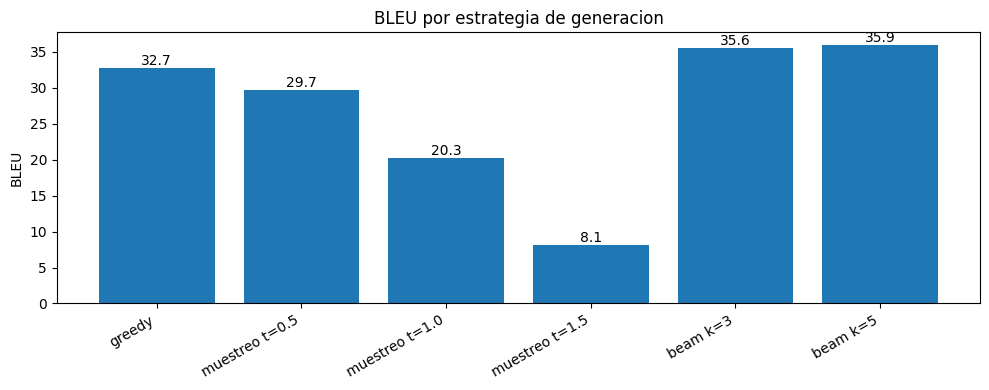

In [57]:
fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.bar(df_estrategias["estrategia"], df_estrategias["bleu"])
ax.bar_label(barras, fmt="%.1f")
ax.set_ylabel("BLEU")
ax.set_title("BLEU por estrategia de generacion")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Miro algunas traducciones de cada estrategia para las mismas frases. 

In [58]:
EJEMPLOS = [0, 1, 2, 3, 4]

for i in EJEMPLOS:
    print(f"EN: {' '.join(test_en[i])}")
    for ref in test_refs[i]:
        print(f"ES ref: {' '.join(ref)}")
    for nombre, hipotesis in salidas.items():
        print(f"{nombre:<18} | {' '.join(hipotesis[i])}")
    print()

EN: if you lie down with dogs you'll get up with fleas
ES ref: el que duerme con perros se levanta con pulgas
ES ref: el que con perros se acuesta con pulgas se despierta
ES ref: el que con perros se acuesta con pulgas se levanta
greedy             | si te das con cuidado con los perros mientras están fuera de pie
muestreo t=0.5     | si tú das con perros <unk> al salir de pie
muestreo t=1.0     | si perdés sales con perros o se te <unk> con un gato
muestreo t=1.5     | si llenas inútiles te coman cubierta con perros
beam k=3           | si te das con perros <unk> al pie
beam k=5           | si <unk> con perros se levanta con pulgas

EN: tom neglected his family
ES ref: tom dejó de lado a su familia
greedy             | tom abandonó a su familia
muestreo t=0.5     | tom abandonó a su familia
muestreo t=1.0     | tomás abandonó a su familia
muestreo t=1.5     | tomás cumple a su familia
beam k=3           | tom abandonó a su familia
beam k=5           | tom abandonó a su familia

EN: i 

Observaciones
* Beam search es la mejor estrategia. Sobre las 2000 frases de test el BLEU sube de 32,7 con greedy a 35,6 con k=3 y a 35,9 con k=5. Casi toda la ganancia está en pasar de 1 a 3, porque de 3 a 5 suma apenas 0,4.
* El costo es el tiempo. Beam va de a una frase y tarda 165 segundos con k=3 y 190 con k=5, contra 4 de greedy en batch.
* El muestreo empeora el BLEU en las tres temperaturas y cuanto más alta peor. Con t=0.5 queda cerca de greedy (29,7) y con t=1.5 cae a 8,1, con frases que cambian palabras al azar ("tomás cumple a su familia"). Para traducir el muestreo no tiene mucho sentido, porque hay una traducción correcta y no se busca variedad, a diferencia del Desafío 3 donde se generaban letras.
* El largo medio casi no cambia entre estrategias. La normalización por largo hace que beam no prefiera frases más cortas, y las traducciones de beam quedan apenas más cortas que las de greedy (5,9 contra 6,0 palabras). Con el muestreo, en cambio, a mayor temperatura las frases salen un poco más largas.

### Implementación en PyTorch

Armo el mismo traductor directamente en PyTorch, con las mismas capas, los mismos hiperparámetros y los mismos datos, para comparar contra la versión de Keras. Keras ya corre con backend torch, así que el motor de cálculo es el mismo, pero todo lo que hace fit hay que escribirlo a mano.

Las diferencias con Keras son estas.
* La capa final devuelve logits sin softmax. CrossEntropyLoss aplica el log-softmax adentro, que es numéricamente más estable.
* El padding lo descarto con ignore_index=PAD en vez de pasar un sample weight, así que las dos losses son comparables.
* El embedding tiene padding_idx=0, que deja fijo en cero el vector del padding.
* El loop de entrenamiento es explícito. Recorro los batches, calculo la loss, hago backward y el paso del optimizador, y después evalúo en validación con model.eval() y sin gradientes para que el dropout no actúe.
* ReduceLROnPlateau de PyTorch baja el learning rate cuando lleva más de patience épocas sin mejorar, mientras que el de Keras lo baja al llegar a patience. Por eso uso patience=1 en PyTorch, que equivale al patience=2 de Keras.
* El early stopping y la restauración del mejor modelo los hago a mano guardando el state_dict de la mejor época.
* Las inicializaciones por defecto no son las mismas. Keras usa glorot y ortogonal en la LSTM y PyTorch una uniforme, así que espero curvas parecidas pero no idénticas.

Para la inferencia el modelo tiene dos métodos aparte del forward. El método "codificar" devuelve los estados del encoder y "paso" avanza el decoder de a un token. Los dos reemplazan a los dos modelos de inferencia en Keras.

In [ ]:
# la version de keras equivalente es la de embeddings al azar con las unidades elegidas
historia_keras = resultados[f"lstm_{UNIDADES_FINAL}"]["historia"]
bleu_keras = resultados[f"lstm_{UNIDADES_FINAL}"]["bleu"]
hip_keras = resultados[f"lstm_{UNIDADES_FINAL}"]["hipotesis"]

from torch import nn
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42)


class Traductor(nn.Module):
    """Encoder-decoder LSTM equivalente al de keras, devuelve logits."""

    def __init__(self, vocab_en_size, vocab_es_size, unidades, dim_en=300, dim_es=400):
        super().__init__()
        self.enc_emb = nn.Embedding(vocab_en_size, dim_en, padding_idx=PAD)
        self.enc_lstm = nn.LSTM(dim_en, unidades, batch_first=True)
        self.dec_emb = nn.Embedding(vocab_es_size, dim_es, padding_idx=PAD)
        self.dec_lstm = nn.LSTM(dim_es, unidades, batch_first=True)
        self.dec_dense = nn.Linear(unidades, vocab_es_size)
        self.dropout = nn.Dropout(0.3)

    def codificar(self, enc):
        _, estado = self.enc_lstm(self.dropout(self.enc_emb(enc)))
        return estado  # (h, c)

    def paso(self, token, estado):
        y, estado = self.dec_lstm(self.dropout(self.dec_emb(token)), estado)
        return self.dec_dense(y), estado

    def forward(self, enc, dec_in):
        # dec_in para Teacher forcing
        return self.paso(dec_in, self.codificar(enc))[0]


def a_tensores(datos):
    """TensorDataset con entrada del encoder, entrada del decoder y target."""
    (enc, dec_in), dec_out = datos["x"], datos["y"]
    return TensorDataset(*(torch.from_numpy(a).long() for a in (enc, dec_in, dec_out)))


def evaluar_torch(modelo, cargador, criterio):
    """Loss promedio por token sin padding sobre todo un conjunto."""
    modelo.eval()
    total, tokens = 0.0, 0
    with torch.no_grad():
        for enc, dec_in, dec_out in cargador:
            enc, dec_in, dec_out = enc.to(DEVICE), dec_in.to(DEVICE), dec_out.to(DEVICE)
            n = (dec_out != PAD).sum().item()
            total += criterio(modelo(enc, dec_in).transpose(1, 2), dec_out).item() * n
            tokens += n
    return total / tokens


def entrenar_torch(modelo, train, val):
    """Entrena con early stopping o carga los pesos y la historia si ya estan guardados."""
    ruta_modelo = CARPETA / "traductor_torch.pt"
    ruta_historia = CARPETA / "historia_torch.json"
    modelo.to(DEVICE)
    if ruta_modelo.exists() and ruta_historia.exists():
        print(f"Cargo {ruta_modelo} sin reentrenar")
        modelo.load_state_dict(torch.load(ruta_modelo, map_location=DEVICE, weights_only=True))
        return modelo, json.loads(ruta_historia.read_text())

    cargador_train = DataLoader(a_tensores(train), batch_size=BATCH_SIZE, shuffle=True)
    cargador_val = DataLoader(a_tensores(val), batch_size=BATCH_SIZE)
    criterio = nn.CrossEntropyLoss(ignore_index=PAD)  # promedio sobre tokens sin padding
    optimizador = torch.optim.Adam(modelo.parameters(), lr=5e-4)
    # patience=1 en torch equivale a patience=2 en keras
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, factor=0.5, patience=1, min_lr=1e-5)

    historia = {"loss": [], "val_loss": [], "val_ppl": []}
    mejor, sin_mejora = float("inf"), 0
    inicio = time.time()
    for epoca in range(EPOCAS):
        t = time.time()
        modelo.train()
        perdidas = []
        for enc, dec_in, dec_out in cargador_train:
            enc, dec_in, dec_out = enc.to(DEVICE), dec_in.to(DEVICE), dec_out.to(DEVICE)
            optimizador.zero_grad()
            # CrossEntropyLoss espera (batch, clases, largo)
            perdida = criterio(modelo(enc, dec_in).transpose(1, 2), dec_out)
            perdida.backward()
            optimizador.step()
            perdidas.append(perdida.item())

        val_loss = evaluar_torch(modelo, cargador_val, criterio)
        scheduler.step(val_loss)
        historia["loss"].append(float(np.mean(perdidas)))
        historia["val_loss"].append(val_loss)
        historia["val_ppl"].append(float(np.exp(val_loss)))
        print(f"Epoca {epoca + 1}/{EPOCAS} | {time.time() - t:.0f}s | loss: {historia['loss'][-1]:.4f} | "
              f"val_loss: {val_loss:.4f} | val_ppl: {historia['val_ppl'][-1]:.2f} | "
              f"lr: {optimizador.param_groups[0]['lr']:.1e}")

        if val_loss < mejor:
            mejor, sin_mejora = val_loss, 0
            torch.save(modelo.state_dict(), ruta_modelo)
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                break

    modelo.load_state_dict(torch.load(ruta_modelo, map_location=DEVICE, weights_only=True))  # mejor epoca
    historia["minutos"] = (time.time() - inicio) / 60
    historia["parametros"] = sum(p.numel() for p in modelo.parameters())
    ruta_historia.write_text(json.dumps(historia))
    print(f"Tiempo: {historia['minutos']:.1f} min | Mejor perplejidad: {min(historia['val_ppl']):.2f}")
    return modelo, historia


modelo_torch = Traductor(len(vocab_en), len(vocab_es), UNIDADES_FINAL, DIM_EN, DIM_ES)
modelo_torch, historia_torch = entrenar_torch(modelo_torch, train, val)

Cargo modelos_desafio4/traductor_torch.pt sin reentrenar


Para traducir uso el mismo greedy en batch que en Keras. Codifico un batch de frases, arranco con el token de inicio y en cada paso me quedo con el índice de mayor logit, que es el mismo que el de mayor probabilidad. Después corto en el fin de frase con la misma función y calculo BLEU sobre el mismo test.

In [34]:
def greedy_torch(modelo, enc_x, idx2es, max_len, batch=512):
    """Traduce un array de frases codificadas eligiendo la palabra mas probable en cada paso."""
    modelo.eval()
    traducciones_out = []
    with torch.no_grad():
        for i in range(0, len(enc_x), batch):
            estado = modelo.codificar(torch.from_numpy(enc_x[i:i + batch]).long().to(DEVICE))
            token = torch.full((len(estado[0][0]), 1), SOS, device=DEVICE)
            pasos = []
            for _ in range(max_len):
                logits, estado = modelo.paso(token, estado)
                token = logits[:, -1].argmax(dim=-1, keepdim=True)
                pasos.append(token[:, 0])
            traducciones_out += [cortar(fila, idx2es) for fila in torch.stack(pasos, dim=1).cpu().numpy()]
    return traducciones_out


hip_torch = greedy_torch(modelo_torch, enc_test, idx2es, MAX_LEN_ES)
bleu_torch = bleu(hip_torch, test_refs)
print(f"BLEU PyTorch: {bleu_torch:.2f} | BLEU Keras: {bleu_keras:.2f}")

BLEU PyTorch: 32.25 | BLEU Keras: 20.45


#### Comparación con Keras

Grafico las curvas de loss y de perplejidad de validación de las dos implementaciones, con un color por framework y la de validación en línea punteada. Después junto en una tabla la mejor perplejidad, las épocas, el tiempo, la cantidad de parámetros y el BLEU de cada una.

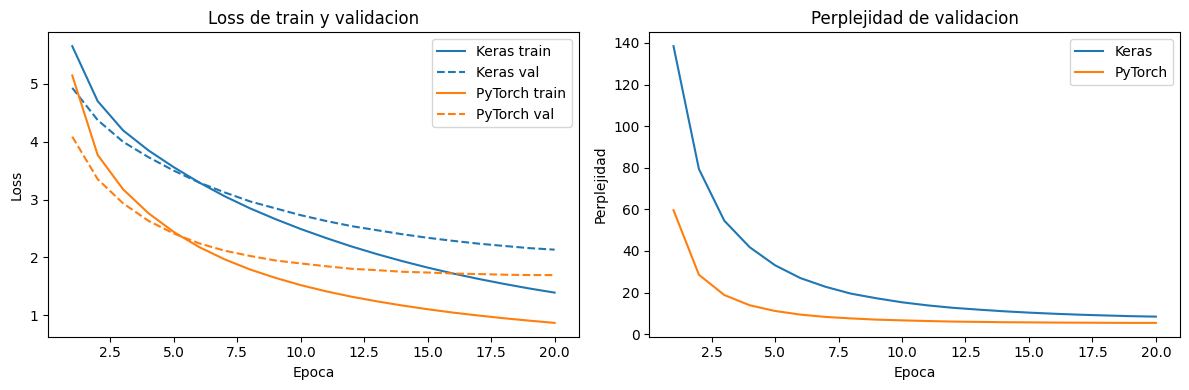

,keras,pytorch
mejor_ppl,8.46,5.45
epocas,20.00,20.00
minutos,126.11,46.26
parametros,21392048.00,21396144.00
bleu,20.45,32.25


In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for nombre, h in [("Keras", historia_keras), ("PyTorch", historia_torch)]:
    epocas = range(1, len(h["loss"]) + 1)
    linea, = ax1.plot(epocas, h["loss"], label=f"{nombre} train")
    ax1.plot(epocas, h["val_loss"], "--", color=linea.get_color(), label=f"{nombre} val")
    ax2.plot(epocas, h["val_ppl"], color=linea.get_color(), label=nombre)
ax1.set_xlabel("Epoca")
ax1.set_ylabel("Loss")
ax1.set_title("Loss de train y validacion")
ax1.legend()
ax2.set_xlabel("Epoca")
ax2.set_ylabel("Perplejidad")
ax2.set_title("Perplejidad de validacion")
ax2.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({
    nombre: {"mejor_ppl": min(h["val_ppl"]), "epocas": len(h["loss"]), "minutos": h["minutos"],
             "parametros": h["parametros"], "bleu": b}
    for nombre, h, b in [("keras", historia_keras, bleu_keras), ("pytorch", historia_torch, bleu_torch)]
}).round(2)

Por último miro las traducciones de las dos implementaciones para las mismas cinco frases de test.

In [36]:
for i in range(0, len(hip_torch), len(hip_torch) // 5)[:5]:
    print(f"Ingles:     {' '.join(test_en[i])}")
    print(f"Referencia: {' '.join(test_refs[i][0])}")
    print(f"Keras:      {' '.join(hip_keras[i])}")
    print(f"PyTorch:    {' '.join(hip_torch[i])}\n")

Ingles:     if you lie down with dogs you'll get up with fleas
Referencia: el que duerme con perros se levanta con pulgas
Keras:      si le <unk> con los perros que se les <unk>
PyTorch:    si salís con perros te <unk> con pulgas

Ingles:     i can't put up with it any longer
Referencia: no lo puedo soportar por más tiempo
Keras:      no puedo soportar más tiempo
PyTorch:    no puedo aguantar más tiempo

Ingles:     tom took mary back home
Referencia: tom llevó a mary hasta su casa
Keras:      tom cogió a mary de casa
PyTorch:    tom volvió a casa a mary en casa

Ingles:     she'd rather be spending time with someone else
Referencia: ella preferiría pasar el tiempo con otra persona
Keras:      de qué hora necesita ser más cuidadoso con alguien
PyTorch:    alguien más tiempo se podría pasar con más tiempo

Ingles:     you must not speak so loudly here
Referencia: no debes hablar tan fuerte aquí
Keras:      no debes hablar tan bien aquí
PyTorch:    no debes hablar de aquí tan alto



Observaciones
* La versión de PyTorch anda bastante mejor que la de keras con la misma arquitectura y los mismos datos. La perplejidad de validación queda en 5,5 contra 8,5 y el BLEU en 32,3 contra 20,5.
* También es casi tres veces más rápida, 46 minutos contra 126. La LSTM de PyTorch usa el kernel nativo de MPS y la de keras con backend torch arma la recurrencia paso a paso.
* Las dos implementaciones llegan al tope de 20 épocas sin cortar, pero la de PyTorch está más cerca de converger. En las últimas épocas la loss de validación casi no baja.

### Conclusiones

De todos los modelos me quedo con el de 512 unidades con embeddings preentrenados con fine tuning, que logra la mejor perplejidad de validación y el mejor BLEU en test. Traduce bien frases cortas y comunes, y en las largas empieza bien y después pierde calidad.

Lo que más cambia el resultado es la cantidad de datos. La réplica de clase con 10.000 pares no llega a funcionar bien, pero la misma red con el corpus completo da mejores resultados, con un BLEU cercano a 19. Después vienen los embeddings preentrenados, que suman unos 12 puntos de BLEU sobre el modelo al azar y por último las unidades de la LSTM, donde subir de 256 a 512 aporta poco más de un punto y medio.

Para generar, beam search es claramente mejor que greedy y el muestreo con temperatura no sirve para traducir. 

Por último, con PyTorch obtuve un modelo casi tres veces más rápido que el de Keras, lo que muestra que detalles como la implementación de la LSTM son importantes a considerar en un escenario en producción.